In [1]:
import utils
import torch.nn as nn

from utils import *
from torchvision import datasets

weights_path = "models_weights"

# Dataset

In [2]:
train_ds = datasets.FashionMNIST(root='datasets', train=True, download=True)
test_ds = datasets.FashionMNIST(root='datasets', train=False, download=True)
x_train, y_train = train_ds.data.numpy(), train_ds.targets.numpy()
x_test, y_test = test_ds.data.numpy(), test_ds.targets.numpy()

class_names = ['0','1','2','3','4','5','6','7','8','9']
x_train = x_train.reshape((60000, 1, 28, 28)) / 255  # channels-first + normalizzazione in [0, 1]
x_test = x_test.reshape((10000, 1, 28, 28)) / 255

# Models

In [3]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

### Model w\o pooling

In [4]:
model_nopool = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(),
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.LazyLinear(64), nn.ReLU(),  # in_features (64 * 22 * 22 = 30976) calcolato al primo forward
    nn.Linear(64, 10)
).to(device)

loss_fn = nn.CrossEntropyLoss()
summary(model_nopool, (1, 28, 28))

optimizer_nopool = torch.optim.Adam(model_nopool.parameters(), lr=1e-3)  # va creato dopo il forward

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 26, 26)             320
1 (ReLU)                    (None, 32, 26, 26)               0
2 (Conv2d)                  (None, 64, 24, 24)          18,496
3 (ReLU)                    (None, 64, 24, 24)               0
4 (Conv2d)                  (None, 64, 22, 22)          36,928
5 (ReLU)                    (None, 64, 22, 22)               0
6 (Flatten)                 (None, 30976)                    0
7 (Linear)                  (None, 64)               1,982,528
8 (ReLU)                    (None, 64)                       0
9 (Linear)                  (None, 10)                     650
Total params: 2,038,922
Trainable params: 2,038,922
Non-trainable params: 0


### Model with pooling

In [5]:
model_conv = nn.Sequential(
    nn.Conv2d(1, 32, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(32, 64, kernel_size=3), nn.ReLU(),
    nn.MaxPool2d(2),
    nn.Conv2d(64, 64, kernel_size=3), nn.ReLU(),
    nn.Flatten(),
    nn.Dropout(0.5),
    nn.LazyLinear(64), nn.ReLU(),  # in_features (64 * 3 * 3 = 576) calcolato al primo forward
    nn.Linear(64, 10)
).to(device)

summary(model_conv, (1, 28, 28))
optimizer_conv = torch.optim.Adam(model_conv.parameters(), lr=1e-3)

Layer (type)                Output Shape               Param #
0 (Conv2d)                  (None, 32, 26, 26)             320
1 (ReLU)                    (None, 32, 26, 26)               0
2 (MaxPool2d)               (None, 32, 13, 13)               0
3 (Conv2d)                  (None, 64, 11, 11)          18,496
4 (ReLU)                    (None, 64, 11, 11)               0
5 (MaxPool2d)               (None, 64, 5, 5)                 0
6 (Conv2d)                  (None, 64, 3, 3)            36,928
7 (ReLU)                    (None, 64, 3, 3)                 0
8 (Flatten)                 (None, 576)                      0
9 (Dropout)                 (None, 576)                      0
10 (Linear)                 (None, 64)                  36,928
11 (ReLU)                   (None, 64)                       0
12 (Linear)                 (None, 10)                     650
Total params: 93,322
Trainable params: 93,322
Non-trainable params: 0


# Training

In [6]:
EPOCHS = 10
VERBOSE = 1
BS = 32

### MODEL WITHOUT POOLING

 20%|██        | 1/5 [00:15<01:02, 15.70s/it]

Epoch 1/5 - loss: 0.4107 - accuracy: 0.8508 - val_loss: 0.3123 - val_accuracy: 0.8911


 40%|████      | 2/5 [00:32<00:48, 16.22s/it]

Epoch 2/5 - loss: 0.2551 - accuracy: 0.9070 - val_loss: 0.2648 - val_accuracy: 0.9027


 60%|██████    | 3/5 [00:49<00:32, 16.48s/it]

Epoch 3/5 - loss: 0.1996 - accuracy: 0.9264 - val_loss: 0.2723 - val_accuracy: 0.9045


 80%|████████  | 4/5 [01:05<00:16, 16.40s/it]

Epoch 4/5 - loss: 0.1543 - accuracy: 0.9427 - val_loss: 0.2632 - val_accuracy: 0.9099


100%|██████████| 5/5 [01:21<00:00, 16.40s/it]

Epoch 5/5 - loss: 0.1174 - accuracy: 0.9561 - val_loss: 0.2857 - val_accuracy: 0.9148


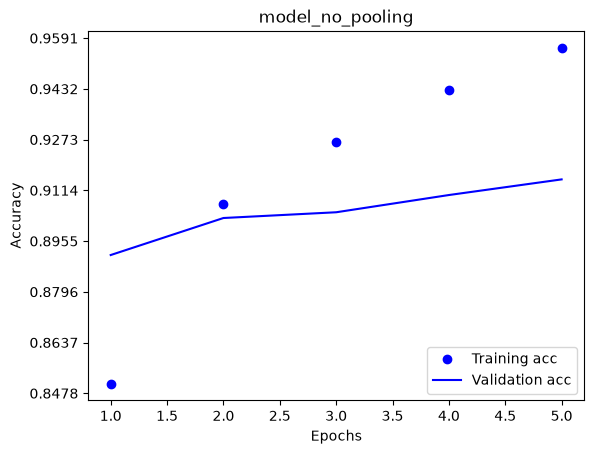

In [7]:
name = "model_no_pooling"

exists = 0#os.path.isfile(f'{weights_path}/{name}.hist') and os.path.isfile(f'{weights_path}/{name}.pt')
if exists:
    with open(f'{weights_path}/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_nopool.load_state_dict(torch.load(f'{weights_path}/{name}.pt', map_location=device))
else:
    history_dict = fit(model_nopool, optimizer_nopool, loss_fn, x_train, y_train, epochs=EPOCHS, verbose=VERBOSE, validation_data = (x_test, y_test), batch_size=BS, device=device)
    with open(f'{weights_path}/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_nopool.state_dict(), f'{weights_path}/{name}.pt')
    
utils.hist_plot(history_dict, name)


### MODEL WITH POOLING

 20%|██        | 1/5 [00:12<00:50, 12.66s/it]

Epoch 1/5 - loss: 0.6100 - accuracy: 0.7697 - val_loss: 0.4094 - val_accuracy: 0.8476


 40%|████      | 2/5 [00:25<00:37, 12.66s/it]

Epoch 2/5 - loss: 0.4076 - accuracy: 0.8496 - val_loss: 0.3489 - val_accuracy: 0.8741


 60%|██████    | 3/5 [00:37<00:25, 12.58s/it]

Epoch 3/5 - loss: 0.3512 - accuracy: 0.8723 - val_loss: 0.3042 - val_accuracy: 0.8895


 80%|████████  | 4/5 [00:50<00:12, 12.47s/it]

Epoch 4/5 - loss: 0.3208 - accuracy: 0.8831 - val_loss: 0.2898 - val_accuracy: 0.8954


100%|██████████| 5/5 [01:02<00:00, 12.56s/it]

Epoch 5/5 - loss: 0.2996 - accuracy: 0.8902 - val_loss: 0.2740 - val_accuracy: 0.8991


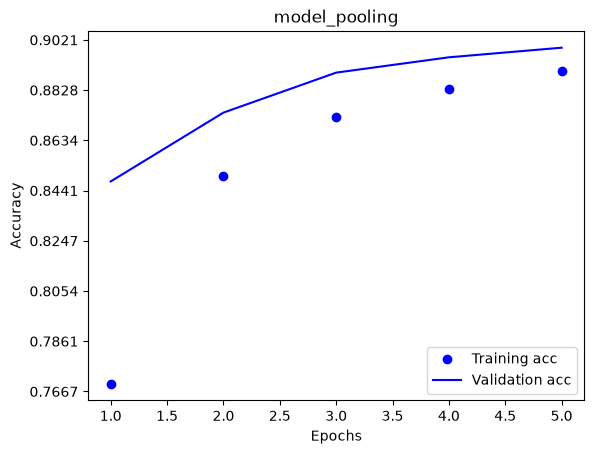

In [8]:
name = "model_pooling"

exists = 0#os.path.isfile(f'{weights_path}/{name}.hist') and os.path.isfile(f'{weights_path}/{name}.pt')
if exists:
    with open(f'{weights_path}/{name}.hist','rb') as hist_file:
        history_dict = pickle.load(hist_file)
    model_conv.load_state_dict(torch.load(f'{weights_path}/{name}.pt', map_location=device))
else:
    history_dict = fit(model_conv, optimizer_conv, loss_fn, x_train, y_train, epochs=EPOCHS, verbose=VERBOSE, validation_data = (x_test, y_test), batch_size=BS, device=device)
    with open(f'{weights_path}/{name}.hist','wb') as hist_file:
        pickle.dump(history_dict, hist_file)
    torch.save(model_conv.state_dict(), f'{weights_path}/{name}.pt')
    
utils.hist_plot(history_dict, name)

In [9]:
x_test_t = torch.as_tensor(x_test, dtype=torch.float32)
y_test_t = torch.as_tensor(y_test, dtype=torch.long)
a = evaluate(model_nopool, x_test_t, y_test_t, loss_fn)
b = evaluate(model_conv, x_test_t, y_test_t, loss_fn)

print(f"{'':<12}{'LOSS':>8}{'ACCURACY':>10}")
print(f"{'NO POOLING':<12}{a[0]:>8.3f}{a[1]:>10.3f}")
print(f"{'POOLING':<12}{b[0]:>8.3f}{b[1]:>10.3f}")

                LOSS  ACCURACY
NO POOLING     0.286     0.915
POOLING        0.274     0.899
